# Competition and data audit

GCI Global 2026 Home Credit Default Risk. Predict the probability of payment difficulties (`TARGET=1`). The supplied README specifies ROC-AUC, submission columns `SK_ID_CURR,TARGET`, and that the **last submitted file** determines the final entry. Its stated deadline is November 20 at 01:00 UTC (07:00 Bangladesh time). These are the local instructions, not a live verification of the competition platform.

Only the supplied CSVs and local column dictionary are used. No external data, hand-labeling, or online reference code. The original notebooks remain unchanged. The local tutorial is the reference for the five-feature baseline; the new modeling code is written for this project.

The validation plan reserves 20% for an untouched audit. Tuning uses only the remaining development data. Fitted transformations, categorical vocabularies and optional group medians are learned inside each training split. Customer IDs are excluded from models.

In [1]:
from pathlib import Path
import sys, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd()/'input/train.csv').exists() else Path.cwd()/'Competition'
assert (ROOT/'input/train.csv').exists(), 'Run from the Competition directory or its parent.'
assert Path(sys.prefix).resolve() == (ROOT/'.venv').resolve(), 'Select the project local venv kernel.'
ART=ROOT/'improvements/artifacts'
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
train=pd.read_csv(ROOT/'input/train.csv'); test=pd.read_csv(ROOT/'input/test.csv')
print('Python:',sys.executable)

Python: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python


In [2]:
display(pd.DataFrame({'rows':[len(train),len(test)],'columns':[train.shape[1],test.shape[1]]},index=['train','test']))
display(pd.read_excel(ROOT/'HomeCredit_columns_description.xlsx'))
target=train.TARGET.value_counts().sort_index().to_frame('count')
target['percent']=100*target['count']/len(train)
display(target)
assert set(train.TARGET.unique())=={0,1}
assert train.SK_ID_CURR.is_unique and test.SK_ID_CURR.is_unique
assert not set(train.SK_ID_CURR)&set(test.SK_ID_CURR)
assert list(train.drop(columns='TARGET').columns)==list(test.columns)
print('Feature duplicates:',train.drop(columns=['SK_ID_CURR','TARGET']).duplicated().sum())
display(train.isna().mean().sort_values(ascending=False).rename('missing_fraction').head(15))

,rows,columns
train,171202,34
test,61500,33


,Row,Description
0,SK_ID_CURR,ID of loan in our sample
1,TARGET,Target variable (1 - client with payment diffi...
2,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving
3,CODE_GENDER,Gender of the client
4,CNT_CHILDREN,Number of children the client has
5,AMT_INCOME_TOTAL,Income of the client
6,AMT_CREDIT,Credit amount of the loan
7,AMT_ANNUITY,Loan annuity
8,AMT_GOODS_PRICE,For consumer loans it is the price of the good...
9,NAME_INCOME_TYPE,"Clients income type (businessman, working, mat..."


,count,percent
TARGET,,
0,157381,91.92708
1,13821,8.07292


Feature duplicates: 0


EXT_SOURCE_1                  0.694665
OWN_CAR_AGE                   0.659992
EXT_SOURCE_3                  0.318840
AMT_REQ_CREDIT_BUREAU_YEAR    0.135022
AMT_REQ_CREDIT_BUREAU_QRT     0.135022
AMT_REQ_CREDIT_BUREAU_MON     0.135022
AMT_REQ_CREDIT_BUREAU_HOUR    0.135022
EXT_SOURCE_2                  0.002155
CNT_FAM_MEMBERS               0.000012
NAME_CONTRACT_TYPE            0.000000
DAYS_LAST_PHONE_CHANGE        0.000000
ORGANIZATION_TYPE             0.000000
REGION_RATING_CLIENT          0.000000
OCCUPATION_TYPE               0.000000
FLAG_WORK_PHONE               0.000000
Name: missing_fraction, dtype: float64

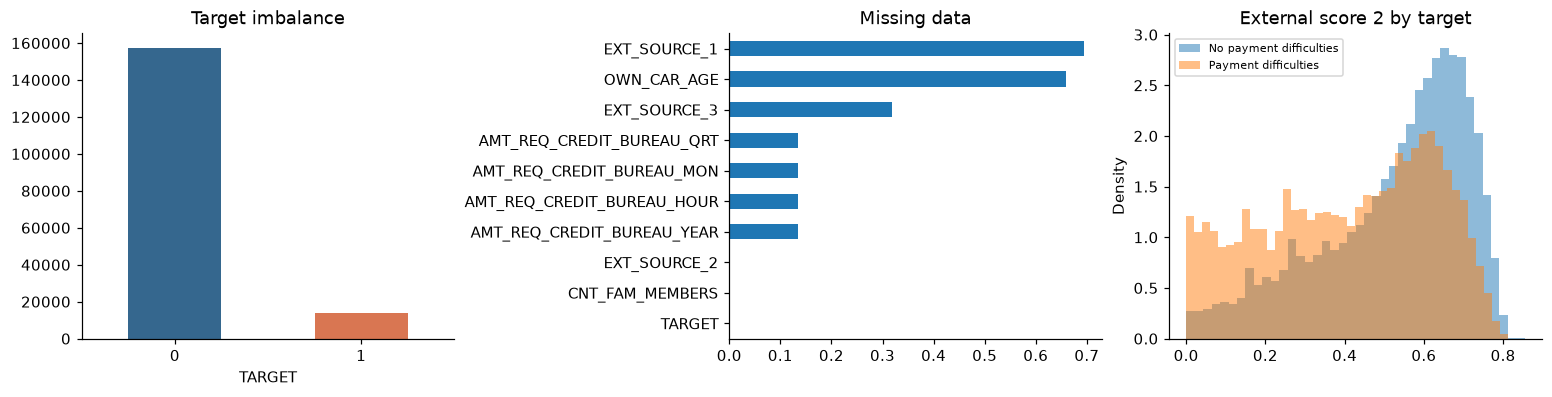

In [3]:
fig,axes=plt.subplots(1,3,figsize=(14,3.5),layout='constrained')
target['count'].plot.bar(ax=axes[0],color=['#35678e','#d97652'],rot=0,title='Target imbalance')
train.isna().mean().sort_values().tail(10).plot.barh(ax=axes[1],title='Missing data')
for value,label in [(0,'No payment difficulties'),(1,'Payment difficulties')]:
    train.loc[train.TARGET.eq(value),'EXT_SOURCE_2'].plot.hist(bins=40,density=True,alpha=.5,ax=axes[2],label=label)
axes[2].legend(fontsize=7); axes[2].set_title('External score 2 by target')
axes[2].set_ylabel('Density')
plt.show()

## Missingness and special values

`DAYS_EMPLOYED=365243` is a sentinel, not a thousand years of employment. Replace it with missing and add an indicator. Preserve informative missingness rather than dropping most rows or imputing all customers identically. The missing car age is retained; no assumption is made that missing age means the client owns no car.

An 8% positive class makes accuracy misleading: predicting zero for every row scores roughly 92% accuracy. Optimize ROC-AUC using probabilities. Average precision and probability calibration metrics are secondary diagnostics. Do not balance the audit or test distributions, and do not apply SMOTE before splitting.

In [4]:
print('Employment sentinel train/test:',train.DAYS_EMPLOYED.eq(365243).mean(),test.DAYS_EMPLOYED.eq(365243).mean())
display(train.groupby(pd.qcut(train.SK_ID_CURR,10),observed=True).TARGET.agg(['size','mean']))
print('Train ID range:',train.SK_ID_CURR.min(),train.SK_ID_CURR.max())
print('Test ID range:',test.SK_ID_CURR.min(),test.SK_ID_CURR.max())

Employment sentinel train/test: 0.18047686358804219 0.17178861788617886


,size,mean
SK_ID_CURR,,
"(-0.001, 17120.1]",17121,0.079143
"(17120.1, 34240.2]",17120,0.083294
"(34240.2, 51360.3]",17120,0.075467
"(51360.3, 68480.4]",17120,0.082185
"(68480.4, 85600.5]",17120,0.079907
"(85600.5, 102720.6]",17120,0.079556
"(102720.6, 119840.7]",17120,0.084171
"(119840.7, 136960.8]",17120,0.080900
"(136960.8, 154080.9]",17120,0.079556


Train ID range: 0 171201
Test ID range: 171202 232701


## Train/test shift

Compare feature missingness, numerical distributions, categorical proportions, and a classifier that tries to distinguish train from test. Exclude the sequential ID: its artificial non-overlap would trivially reveal the source. A near-0.5 adversarial AUC supports random stratified validation but cannot prove the absence of hidden or target shift. Large samples can give small p-values for negligible differences, so inspect effect sizes.

In [5]:
from scipy.stats import ks_2samp
numeric=train.select_dtypes(include='number').columns.difference(['SK_ID_CURR','TARGET'])
shift=[]
for c in numeric:
    a=train[c].dropna(); b=test[c].dropna()
    ks=ks_2samp(a,b)
    shift.append({'feature':c,'KS_statistic':ks.statistic,'train_missing':train[c].isna().mean(),'test_missing':test[c].isna().mean()})
shift=pd.DataFrame(shift).sort_values('KS_statistic',ascending=False)
display(shift.head(12)); shift.to_csv(ART/'numeric_shift.csv',index=False)
cat_shift=[]
for c in train.select_dtypes(include=['object','str']).columns:
    a=train[c].fillna('__MISSING__').value_counts(normalize=True)
    b=test[c].fillna('__MISSING__').value_counts(normalize=True)
    idx=a.index.union(b.index)
    cat_shift.append({'feature':c,'total_variation_distance':.5*(a.reindex(idx,fill_value=0)-b.reindex(idx,fill_value=0)).abs().sum(),'unseen_test_categories':len(set(b.index)-set(a.index))})
display(pd.DataFrame(cat_shift).sort_values('total_variation_distance',ascending=False))

,feature,KS_statistic,train_missing,test_missing
17,EXT_SOURCE_3,0.029286,0.318840,0.320163
16,EXT_SOURCE_2,0.022611,0.002155,0.002114
15,EXT_SOURCE_1,0.021960,0.694665,0.697756
10,DAYS_BIRTH,0.013815,0.000000,0.000000
21,OWN_CAR_AGE,0.012368,0.659992,0.665187
11,DAYS_EMPLOYED,0.011450,0.000000,0.000000
2,AMT_GOODS_PRICE,0.011219,0.000000,0.000000
13,DAYS_LAST_PHONE_CHANGE,0.009841,0.000000,0.000000
18,FLAG_EMP_PHONE,0.008652,0.000000,0.000000
14,DAYS_REGISTRATION,0.007883,0.000000,0.000000


,feature,total_variation_distance,unseen_test_categories
7,ORGANIZATION_TYPE,0.016128,0
6,OCCUPATION_TYPE,0.015271,0
2,NAME_INCOME_TYPE,0.012278,0
1,CODE_GENDER,0.008387,0
3,NAME_EDUCATION_TYPE,0.008186,0
4,NAME_FAMILY_STATUS,0.006960,0
5,NAME_HOUSING_TYPE,0.003171,0
0,NAME_CONTRACT_TYPE,0.001926,0


In [6]:
import sys
sys.path.insert(0,str(ROOT/'improvements'))
from experiment import features, Encoder, SEED
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier
both=pd.concat([train.drop(columns='TARGET'),test],ignore_index=True)
source=np.r_[np.zeros(len(train),dtype=int),np.ones(len(test),dtype=int)]
x=features(both,'raw')
a,b=train_test_split(np.arange(len(source)),test_size=.25,stratify=source,random_state=SEED)
enc=Encoder().fit(x.iloc[a])
adversary=LGBMClassifier(n_estimators=150,num_leaves=15,min_child_samples=200,learning_rate=.05,verbosity=-1,n_jobs=2,random_state=SEED)
adversary.fit(enc.transform(x.iloc[a]),source[a])
adversarial_auc=roc_auc_score(source[b],adversary.predict_proba(enc.transform(x.iloc[b]))[:,1])
print('Train-versus-test adversarial AUC:',round(adversarial_auc,6))
(ART/'data_audit.json').write_text(json.dumps({'adversarial_auc':adversarial_auc,'train_rows':len(train),'test_rows':len(test),'positive_rate':train.TARGET.mean()},indent=2))

/Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train-versus-test adversarial AUC: 0.518898


129

## Modeling decisions

Use all 32 customer features, retain missing values for trees, add financial and lifetime ratios and external-score summaries, and compare against unengineered data. Try regularized LightGBM, native-categorical CatBoost, and logistic regression. Optional category frequencies and group medians are fitted separately inside each split. Neither test rows nor validation targets are used to fit those transformations.

Tune on development data, verify finalists with five-fold stratified CV, choose a simple blend only if it improves pooled out-of-fold AUC, then evaluate the frozen choice once on the untouched audit. Final five-fold models use all labeled data and fixed iteration counts chosen during development. This reduces randomness and retains every labeled row for learning in four folds. Keep the independent audit as the primary estimate; final full-data OOF predictions are a diagnostic because their development labels already influenced selection.